In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rc
import astropy.units as u
import astropy.coordinates as coord
import astropy as ap
from astropy.coordinates import SkyCoord

df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')


In [18]:

df1["Age0"]=df1["Age"].str.split(" ±").str[0].astype(float)
df1["Age_error"]=df1["Age"].str.split(" ±").str[1].astype(float)
df1["Name"] = "NGC " + df1["NGC"].astype(float).astype("Int64").astype(str)
harris_p2["ID"] = harris_p2["ID"].astype(str).str.strip().str.upper()
df1["Name"] = df1["Name"].astype(str).str.strip().str.upper()
rc('text', usetex=False)
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
X = pd.to_numeric(harris_p1['X'],errors='coerce')
Y = pd.to_numeric(harris_p1['Y'],errors='coerce')
Z = pd.to_numeric(harris_p1['Z'],errors='coerce')
Ra = pd.to_numeric(harris_p1['RA'],errors='coerce')
Dec = pd.to_numeric(harris_p1['DEC'],errors='coerce')
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
rho_0 = pd.to_numeric(harris_p3['rho_0'],errors='coerce')
mu_V = pd.to_numeric(harris_p3['mu_V'],errors='coerce')
c = pd.to_numeric(harris_p3['c'],errors='coerce')
BmV = pd.to_numeric(harris_p2['B-V'],errors='coerce')
ellip = pd.to_numeric(harris_p2['ellip'],errors='coerce')
r_c = pd.to_numeric(harris_p3['r_c'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
V_t = pd.to_numeric(harris_p2['V_t'],errors='coerce')
wt = pd.to_numeric(harris_p2['wt'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
v_LSR= pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
mask = mtlc > -0.8
log_tc= pd.to_numeric(harris_p3['lg_tc'],errors='coerce')
log_th= pd.to_numeric(harris_p3['lg_th'],errors='coerce')
## Copied of Tobias
VmR = pd.to_numeric(harris_p2['V-R'],errors='coerce')
UmB = pd.to_numeric(harris_p2['U-B'],errors='coerce')
VmI = pd.to_numeric(harris_p2['V-I'],errors='coerce')
V_hb = pd.to_numeric(harris_p2['V_HB'],errors='coerce')
## Correct colour values for foreground reddening
E_BmV = pd.to_numeric(harris_p2['E(B-V)'],errors='coerce')
BmV0=BmV - E_BmV
VmR0=VmR - 0.72*E_BmV
VmI0=VmI - 1.24*E_BmV
UmB0=UmB - 0.72*E_BmV
#Coefficients calculated from Cardelli et al. 1989, ApJ, 345, 245
Age = pd.to_numeric(df1['Age0'],errors='coerce')
Age_e = pd.to_numeric(df1['Age_error'],errors='coerce') 
#Convert RA and DEC to degrees

Ra_rad = coord.Angle(Ra, unit=u.hourangle).rad
Dec_rad = coord.Angle(Dec, unit=u.degree).rad


In [19]:
## Merge age and harris dataframes
merged_df=harris_p1
merged_df['RA'] = coord.Angle(merged_df['RA'], unit=u.hourangle).rad
merged_df['DEC'] = coord.Angle(merged_df['DEC'], unit=u.degree).rad


Saggitarius Stream Stuff. Lots of code taken other people and documents.

In [20]:
#Plotting the Saggitarius Stream. 
from astropy.coordinates import frame_transform_graph, rotation_matrix
class Sagittarius(coord.BaseCoordinateFrame):
    """A Heliocentric spherical coordinate system defined by the orbit
    of the Sagittarius dwarf galaxy, as described in
        https://ui.adsabs.harvard.edu/abs/2003ApJ...599.1082M
    and further explained in
        https://www.stsci.edu/~dlaw/Sgr/.

    Parameters
    ----------
    representation : `~astropy.coordinates.BaseRepresentation` or None
        A representation object or None to have no data (or use the other keywords)
    Lambda : `~astropy.coordinates.Angle`, optional, must be keyword
        The longitude-like angle corresponding to Sagittarius' orbit.
    Beta : `~astropy.coordinates.Angle`, optional, must be keyword
        The latitude-like angle corresponding to Sagittarius' orbit.
    distance : `~astropy.units.Quantity`, optional, must be keyword
        The Distance for this object along the line-of-sight.
    pm_Lambda_cosBeta : `~astropy.units.Quantity`, optional, must be keyword
        The proper motion along the stream in ``Lambda`` (including the
        ``cos(Beta)`` factor) for this object (``pm_Beta`` must also be given).
    pm_Beta : `~astropy.units.Quantity`, optional, must be keyword
        The proper motion in Declination for this object (``pm_ra_cosdec`` must
        also be given).
    radial_velocity : `~astropy.units.Quantity`, optional, keyword-only
        The radial velocity of this object.
    """
    default_representation = coord.SphericalRepresentation
    default_differential = coord.SphericalCosLatDifferential
    frame_specific_representation_info = {
        coord.SphericalRepresentation: [
            coord.RepresentationMapping("lon", "Lambda"),
            coord.RepresentationMapping("lat", "Beta"),
            coord.RepresentationMapping("distance", "distance"),
        ]
    }
SGR_PHI = (180 + 3.75) * u.degree  # Euler angles (from Law & Majewski 2010)
SGR_THETA = (90 - 13.46) * u.degree
SGR_PSI = (180 + 14.111534) * u.degree
SGR_MATRIX = (
    np.diag([1.0, 1.0, -1.0])
    @ rotation_matrix(SGR_PSI, "z")
    @ rotation_matrix(SGR_THETA, "x")
    @ rotation_matrix(SGR_PHI, "z")
)
@frame_transform_graph.transform(
    coord.StaticMatrixTransform, coord.Galactic, Sagittarius
)
def galactic_to_sgr():
    """Compute the Galactic spherical to heliocentric Sgr transformation matrix."""
    return SGR_MATRIX
@frame_transform_graph.transform(
    coord.StaticMatrixTransform, Sagittarius, coord.Galactic
)
def sgr_to_galactic():
    """Compute the heliocentric Sgr to spherical Galactic transformation matrix."""
    return SGR_MATRIX.swapaxes(-2, -1)


    
##Code sourced from Astropy document "Create a new coordinate class (for the Sagittarius stream)"

icrs = coord.SkyCoord(280.161732 * u.degree, 11.91934 * u.degree, frame="icrs")
sgr = icrs.transform_to(Sagittarius)
sgr = coord.SkyCoord(
    Lambda=np.linspace(0, 2 * np.pi, 128) * u.radian,
    Beta=np.zeros(128) * u.radian,
    frame="sagittarius",
)
icrs = sgr.transform_to(coord.ICRS)


In [21]:
#Create Candidate List

candidate_list= np.array(["WHITING 1", "AM 1", "ERIDANUS", "NGC 2419", "PAL 3", "PAL 4", "KO 1", "PAL 14", "NGC 7492", "NGC 4590", "NGC 5024", "NGC 5053", "NGC 362", "NGC 1261", "NGC 6453", "NGC 2419", "NGC 4372", "NGC 6287"])
candidate_df = merged_df[merged_df["ID"].isin(candidate_list)].copy()

candidate_df

,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z
2,NGC 362,NaN,0.275926,-1.236544,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2
4,NGC 1261,NaN,0.838937,-0.963705,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9
6,AM 1,E 1,1.025548,-0.865950,258.34,-48.47,123.3,124.6,-16.5,-80.1,-92.3
12,NGC 2419,NaN,1.999018,0.678627,180.37,25.24,82.6,89.9,-74.7,-0.5,35.2
22,NGC 4372,NaN,3.253977,-1.268139,300.99,-9.88,5.8,7.1,2.9,-4.9,-1.0
24,NGC 4590,M 68,3.313797,-0.466772,299.63,36.05,10.3,10.2,4.1,-7.2,6.0
26,NGC 5024,M 53,3.459770,0.317094,332.96,79.76,17.9,18.4,2.8,-1.4,17.6
27,NGC 5053,NaN,3.475175,0.308928,335.70,78.95,17.4,17.8,3.0,-1.4,17.1
65,NGC 6287,NaN,4.473070,-0.396336,0.13,11.02,9.4,2.1,9.2,0.0,1.8
97,NGC 6453,NaN,4.672515,-0.603869,355.72,-3.87,11.6,3.7,11.5,-0.9,-0.8


In [22]:
#Turn coords into GC
icrs_gc = SkyCoord(
    ra=candidate_df["RA"].to_numpy() * u.rad,
    dec=candidate_df["DEC"].to_numpy() * u.rad,
    frame="icrs"
)

# Transform to Sagg frame
sgr_gc = icrs_gc.transform_to(sgr.frame)

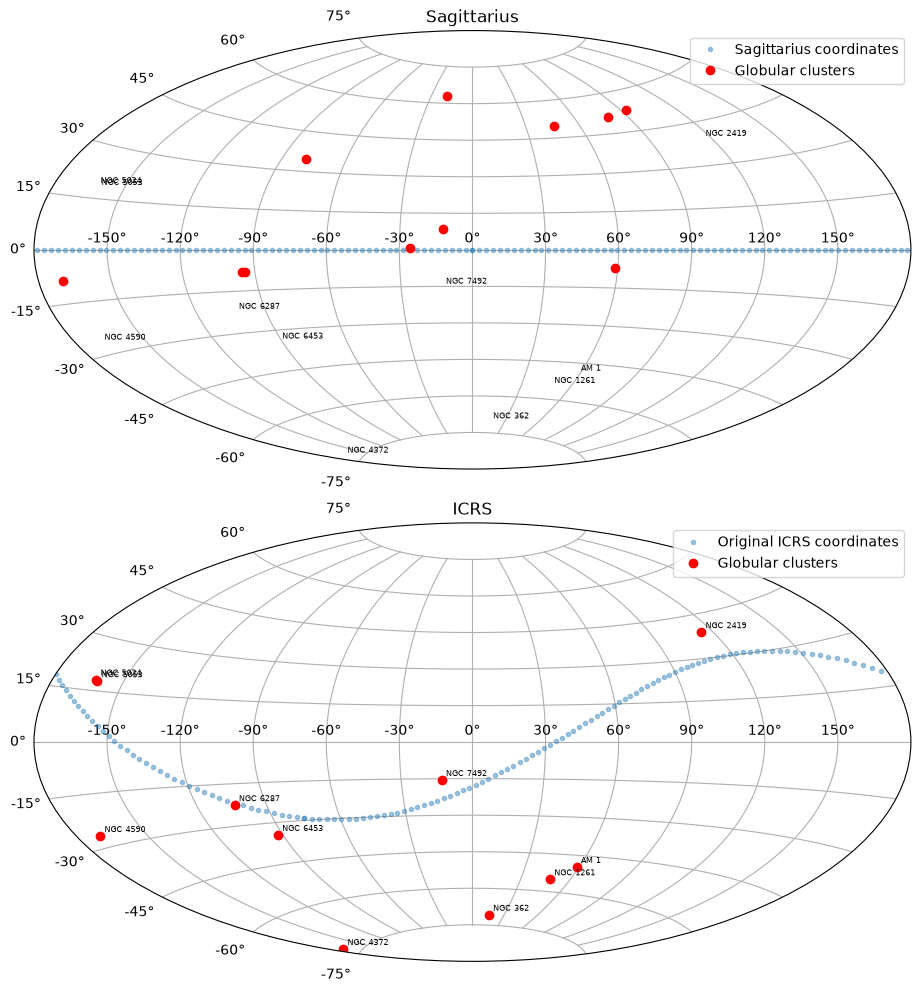

In [27]:
#Plot it all
fig, axes = plt.subplots(
    2, 1, figsize=(10, 10),
    subplot_kw={"projection": "aitoff"}
)

# Sagittarius coords
axes[0].plot(
    sgr.Lambda.wrap_at(180 * u.deg).radian,
    sgr.Beta.radian,
    linestyle="none", marker=".", alpha=0.4,
    label="Sagittarius coordinates"
)

#My GCs
axes[0].plot(
    sgr_gc.Lambda.wrap_at(180 * u.deg).radian,
    sgr_gc.Beta.radian,
    linestyle="none", marker="o", color="red",
    markersize=6, label="Globular clusters"
)

axes[0].set_title("Sagittarius")
axes[0].grid(True)
axes[0].legend()

#ICRS coords
axes[1].plot(
    icrs.ra.wrap_at(180 * u.deg).radian,
    icrs.dec.radian,
    linestyle="none", marker=".", alpha=0.4,
    label="Original ICRS coordinates"
)
#My GCs
axes[1].plot(
    icrs_gc.ra.wrap_at(180 * u.deg).radian,
    icrs_gc.dec.radian,
    linestyle="none", marker="o", color="red",
    markersize=6, label="Globular clusters"
)

axes[1].set_title("ICRS")
axes[1].grid(True)
axes[1].legend()

for i, name in enumerate(candidate_df["ID"]):

    axes[0].annotate(
            name,
            (
                icrs_gc.ra.wrap_at(180 * u.deg).radian[i],
                icrs_gc.dec.radian[i]
            ),
            fontsize=6,
            xytext=(3, 3),
            textcoords="offset points"
        )
    
    axes[1].annotate(
        name,
        (
            icrs_gc.ra.wrap_at(180 * u.deg).radian[i],
            icrs_gc.dec.radian[i]
        ),
        fontsize=6,
        xytext=(3, 3),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()